# PolyGen | Week 2 — Reference-Color Texture Mapping

**Input:** `polygen_asset_bundle.zip` exported from the Week 1 notebook (or a `.glb` plus its reference `.png`).  
**Output:** A UV-textured `polygen_model.glb`, texture atlas PNG, and downloadable ZIP for your React viewer.

This notebook uses **image-guided texture projection**: it transfers observed colors from the reference image onto the mesh, and uses a representative color on unseen surfaces. It is **not** a diffusion-based AI paint model. One image cannot reveal the actual back/sides. It works on a **CPU-only Colab runtime**, so no T4 GPU quota is needed.  

Run cells top to bottom. To align the image with the mesh, adjust the camera angles in Section 4 and rerun Sections 5–8.

## 1. Install lightweight texturing dependencies

In [ ]:
import sys, subprocess
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                'trimesh>=4.4', 'xatlas>=0.0.9', 'Pillow',
                'numpy', 'scipy', 'opencv-python-headless', 'plotly'], check=True)
print('Dependencies installed.')

Dependencies installed.


## 2. Upload the Week 1 bundle (or GLB and reference PNG)

Saving polygen_asset_bundle (3).zip to polygen_asset_bundle (3) (1).zip
GLB: /content/polygen/week2/inputs/polygen_model.glb
Reference: /content/polygen/week2/inputs/inputs/foreground_rgba.png


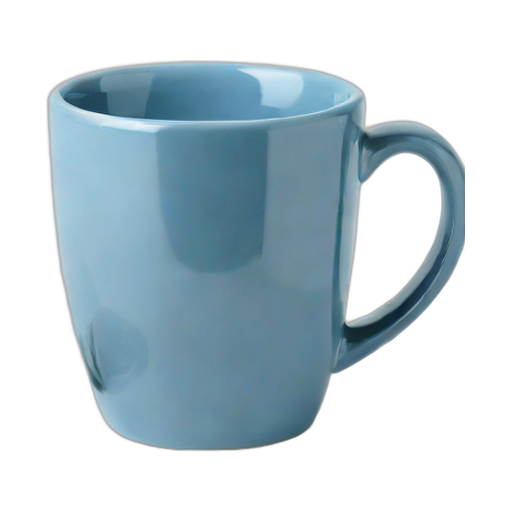

In [ ]:
from pathlib import Path
from google.colab import files
from IPython.display import display
from PIL import Image
import zipfile, shutil

ROOT = Path('/content/polygen/week2')
INPUTS = ROOT / 'inputs'
OUTPUTS = ROOT / 'outputs'
for folder in (INPUTS, OUTPUTS):
    folder.mkdir(parents=True, exist_ok=True)

uploaded = files.upload()
if not uploaded:
    raise RuntimeError('Upload the Week 1 bundle ZIP, or a GLB plus reference PNG.')
for name, data in uploaded.items():
    destination = INPUTS / Path(name).name
    destination.write_bytes(data)
    if destination.suffix.lower() == '.zip':
        with zipfile.ZipFile(destination) as zf:
            for member in zf.infolist():
                safe_name = Path(member.filename)
                if member.is_dir() or safe_name.is_absolute() or '..' in safe_name.parts:
                    continue
                if safe_name.suffix.lower() not in ('.glb', '.png', '.jpg', '.jpeg', '.json', '.obj'):
                    continue
                target = INPUTS / safe_name
                target.parent.mkdir(parents=True, exist_ok=True)
                with zf.open(member) as source, target.open('wb') as sink:
                    shutil.copyfileobj(source, sink)

glbs = sorted(INPUTS.rglob('*.glb'), key=lambda p: (p.name != 'polygen_model.glb',p.name != 'model_raw.glb'))
images = sorted((p for p in INPUTS.rglob('*') if p.suffix.lower() in ('.png','.jpg','.jpeg')),
                key=lambda p: (p.name != 'foreground_rgba.png',p.name != 'reference_image.png'))
if not glbs:
    raise FileNotFoundError('No GLB file found. Upload polygen_model.glb or the Week 1 asset bundle.')
if not images:
    raise FileNotFoundError('No reference image found. Upload reference_image.png or the Week 1 asset bundle.')
MODEL_PATH, IMAGE_PATH = glbs[0], images[0]
print('GLB:', MODEL_PATH)
print('Reference:', IMAGE_PATH)
display(Image.open(IMAGE_PATH).convert('RGBA'))

## 3. Load and check the 3D mesh

In [ ]:
import trimesh, numpy as np
scene = trimesh.load(str(MODEL_PATH), force='scene')
mesh = scene.to_mesh()
if mesh is None or len(mesh.faces)==0 or len(mesh.vertices)==0:
    raise ValueError('The uploaded GLB has no usable mesh geometry.')
if not np.isfinite(mesh.vertices).all():
    raise ValueError('The mesh has invalid vertex coordinates.')
mesh = mesh.copy()
print('Vertices:', len(mesh.vertices))
print('Faces:', len(mesh.faces))
print('Dimensions:', mesh.bounding_box.extents.round(3).tolist())

Vertices: 517027
Faces: 1034060
Dimensions: [3.0, 2.598, 2.444]


## 4. Choose alignment and texture settings

Rotate the virtual camera until the source photo is approximately aligned with the model. If the resulting image texture looks mirrored, change `CAMERA_YAW_DEG` from positive to negative. `MAX_FACES` is optional simplification for speed; set it to `0` to preserve all geometry.

In [ ]:

CAMERA_YAW_DEG = 15.0
CAMERA_PITCH_DEG = 15.0

TEXTURE_SIZE = 1024
MAX_FACES = 50000

ROUGHNESS = 0.25
METALLIC = 0.0

assert TEXTURE_SIZE in (512, 1024, 2048)
print('Yaw:', CAMERA_YAW_DEG, '| Pitch:', CAMERA_PITCH_DEG)

Yaw: 15.0 | Pitch: 15.0


## 5. Prepare the source image and UV unwrap

In [ ]:
import xatlas
from PIL import Image, ImageOps

source = ImageOps.exif_transpose(Image.open(IMAGE_PATH)).convert('RGBA')
rgba = np.asarray(source)
alpha = rgba[:,:,3]
if np.count_nonzero(alpha > 32) < 100:
    raise ValueError('Reference image is empty or almost completely transparent.')

selected = rgba[alpha > 160, :3]
if len(selected) < 100:
    selected = rgba[alpha > 32, :3]
base_rgb = np.median(selected.astype(np.float32),axis=0)
print('Representative backside color:',np.rint(base_rgb).astype(int).tolist())

work_mesh = mesh.copy()
if MAX_FACES > 0 and len(work_mesh.faces) > MAX_FACES:
    try:
        work_mesh = work_mesh.simplify_quadric_decimation(face_count=MAX_FACES)
        print('Mesh simplified to',len(work_mesh.faces),'faces for UV baking.')
    except Exception as exc:
        print('Simplification skipped:',str(exc)[:160])

vmapping, uv_faces, uvs = xatlas.parametrize(
    np.asarray(work_mesh.vertices,dtype=np.float32),
    np.asarray(work_mesh.faces,dtype=np.uint32)
)
vertices = np.asarray(work_mesh.vertices)[vmapping].astype(np.float32)
uv_faces = np.asarray(uv_faces,dtype=np.int64)
uvs = np.asarray(uvs,dtype=np.float32)
uv_mesh = trimesh.Trimesh(vertices=vertices,faces=uv_faces,process=False)
print('UV charts generated. Vertices:',len(vertices),'Faces:',len(uv_faces))

Representative backside color: [106, 140, 157]
Simplification skipped: No module named 'fast_simplification'
UV charts generated. Vertices: 769592 Faces: 1034060


## 6. Project reference colors and bake a UV texture atlas

/tmp/ipykernel_604/3535025989.py:80: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(tex,'RGB').save(TEXTURE_PATH)


Baked texture: /content/polygen/week2/outputs/polygen_basecolor.png
Bake seconds: 587.0
Coverage: 57.3 % of atlas pixels before padding


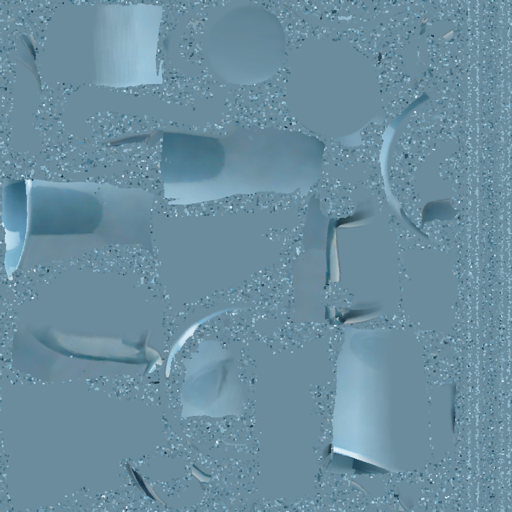

In [ ]:
import numpy as np, math, time
from PIL import Image
from scipy.ndimage import distance_transform_edt

start = time.perf_counter()
H,W = rgba.shape[:2]
yaw = math.radians(CAMERA_YAW_DEG)
pitch = math.radians(CAMERA_PITCH_DEG)
view = np.array([math.sin(yaw)*math.cos(pitch), math.sin(pitch),
                 math.cos(yaw)*math.cos(pitch)],dtype=np.float32)
right = np.cross([0,1,0],view).astype(np.float32)
right /= np.linalg.norm(right)
up = np.cross(view,right).astype(np.float32)
up /= np.linalg.norm(up)
center = vertices.mean(axis=0)
centered = vertices-center
proj_x = centered @ right
proj_y = centered @ up
range_x = max(float(np.ptp(proj_x)),1e-5)
range_y = max(float(np.ptp(proj_y)),1e-5)
ys,xs = np.where(alpha > 32)
min_x,max_x = float(xs.min()),float(xs.max())
min_y,max_y = float(ys.min()),float(ys.max())
margin = 0.97
box_w = (max_x-min_x)*margin
box_h = (max_y-min_y)*margin
cx = (min_x+max_x)/2
cy = (min_y+max_y)/2

tex = np.zeros((TEXTURE_SIZE,TEXTURE_SIZE,3),dtype=np.uint8)
coverage = np.zeros((TEXTURE_SIZE,TEXTURE_SIZE),dtype=bool)
uvpix = np.column_stack([uvs[:,0],1-uvs[:,1]])*(TEXTURE_SIZE-1)
fnormals = uv_mesh.face_normals.astype(np.float32)
source_rgb = rgba[:,:,:3]

for fi,(a,b,c) in enumerate(uv_faces):
    tri = uvpix[[a,b,c]].astype(np.float64)
    x0=max(0,int(np.floor(np.min(tri[:,0]))))
    x1=min(TEXTURE_SIZE-1,int(np.ceil(np.max(tri[:,0]))))
    y0=max(0,int(np.floor(np.min(tri[:,1]))))
    y1=min(TEXTURE_SIZE-1,int(np.ceil(np.max(tri[:,1]))))
    if x0>x1 or y0>y1:
        continue
    p0,p1,p2=tri
    den=((p1[1]-p2[1])*(p0[0]-p2[0])+(p2[0]-p1[0])*(p0[1]-p2[1]))
    if abs(den)<1e-9:
        continue
    grid_y,grid_x=np.mgrid[y0:y1+1,x0:x1+1]
    w0=((p1[1]-p2[1])*(grid_x-p2[0])+(p2[0]-p1[0])*(grid_y-p2[1]))/den
    w1=((p2[1]-p0[1])*(grid_x-p2[0])+(p0[0]-p2[0])*(grid_y-p2[1]))/den
    w2=1-w0-w1
    inside=(w0 >= -1e-5)&(w1 >= -1e-5)&(w2 >= -1e-5)
    if not inside.any():
        continue
    iy,ix=np.nonzero(inside)
    b0,b1,b2=w0[iy,ix],w1[iy,ix],w2[iy,ix]
    point = b0[:,None]*vertices[a]+b1[:,None]*vertices[b]+b2[:,None]*vertices[c]
    point = point-center
    px=cx+((point@right)-(float(proj_x.max())+float(proj_x.min()))/2)/range_x*box_w
    py=cy-((point@up)-(float(proj_y.max())+float(proj_y.min()))/2)/range_y*box_h
    ref_x=np.clip(np.rint(px).astype(int),0,W-1)
    ref_y=np.clip(np.rint(py).astype(int),0,H-1)
    observed=source_rgb[ref_y,ref_x].astype(np.float32)
    opacity=alpha[ref_y,ref_x].astype(np.float32)/255.
    facing=float(np.dot(fnormals[fi],view))
    confidence=np.clip((facing-0.02)/0.55,0,1)*opacity
    painted=np.rint(observed*confidence[:,None]+base_rgb[None,:]*(1-confidence[:,None])).astype(np.uint8)
    tex[grid_y[iy,ix],grid_x[iy,ix]]=painted
    coverage[grid_y[iy,ix],grid_x[iy,ix]]=True

if not coverage.any():
    raise RuntimeError('Texture baking failed: no atlas pixels were painted.')

empty = ~coverage
if empty.any():
    _, nearest = distance_transform_edt(empty,return_indices=True)
    tex[empty]=tex[nearest[0][empty],nearest[1][empty]]

TEXTURE_PATH = OUTPUTS / 'polygen_basecolor.png'
Image.fromarray(tex,'RGB').save(TEXTURE_PATH)
print('Baked texture:',TEXTURE_PATH)
print('Bake seconds:',round(time.perf_counter()-start,1))
print('Coverage:',round(100*coverage.mean(),1),'% of atlas pixels before padding')
from IPython.display import display
display(Image.open(TEXTURE_PATH).resize((512,512)))

## 7. Export and validate a textured GLB

In [ ]:
from trimesh.visual import TextureVisuals
from trimesh.visual.material import PBRMaterial
from PIL import Image

material=PBRMaterial(
    baseColorFactor=[255,255,255,255],
    baseColorTexture=Image.open(TEXTURE_PATH).convert('RGB'),
    metallicFactor=float(METALLIC),
    roughnessFactor=float(ROUGHNESS),
    doubleSided=True,
)
uv_mesh.visual=TextureVisuals(uv=uvs,material=material)
GLB_PATH=OUTPUTS/'polygen_model.glb'
uv_mesh.export(str(GLB_PATH))

check=trimesh.load(str(GLB_PATH),force='scene')
checked=check.to_mesh()
if checked is None or len(checked.faces)==0:
    raise RuntimeError('Exported GLB contains no mesh.')
if checked.visual.kind != 'texture' or checked.visual.material.baseColorTexture is None:
    raise RuntimeError('GLB did not retain its UV base-color texture.')
print('Textured GLB:',GLB_PATH)
print('Faces:',len(checked.faces))
print('Size:',round(GLB_PATH.stat().st_size/1024**2,2),'MB')
print('UV and embedded texture: VERIFIED')

Textured GLB: /content/polygen/week2/outputs/polygen_model.glb
Faces: 1034060
Size: 27.18 MB
UV and embedded texture: VERIFIED


## 8. Download the asset bundle

In [ ]:
import zipfile,json
from google.colab import files

REPORT_PATH=OUTPUTS/'week2_texture_report.json'
REPORT_PATH.write_text(json.dumps({
    'stage':'week2_reference_color_projection',
    'source_glb':MODEL_PATH.name,
    'reference_image':IMAGE_PATH.name,
    'bake_method':'single_view_projective_uv_bake',
    'texture_resolution':TEXTURE_SIZE,
    'yaw_degrees':CAMERA_YAW_DEG,
    'pitch_degrees':CAMERA_PITCH_DEG,
    'vertices':len(uv_mesh.vertices),
    'faces':len(uv_mesh.faces),
    'limitations':'Visible reference-image colors; other surfaces use representative color. No diffusion paint model.'
},indent=2),encoding='utf-8')
ZIP_PATH=OUTPUTS/'polygen_week2_textured_bundle.zip'
with zipfile.ZipFile(ZIP_PATH,'w',compression=zipfile.ZIP_DEFLATED) as zf:
    for path in (GLB_PATH,TEXTURE_PATH,REPORT_PATH):
        zf.write(path,arcname=path.name)
print('Bundle:',ZIP_PATH)
files.download(str(ZIP_PATH))

Bundle: /content/polygen/week2/outputs/polygen_week2_textured_bundle.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Open the textured model in your React viewer

Extract `polygen_model.glb` from the downloaded ZIP and replace the previous file at:

`E:\GENERATIVE AI\1.1PROJECTS\POLYGEN\frontend\public\models\polygen_model.glb`

Your current `ModelViewer.jsx` already loads `/models/polygen_model.glb`, so **no React code change is required**. Use `npm run dev` in `frontend/` and hard-refresh the browser.

If the colors appear on the wrong side, change the camera yaw/pitch in Section 4 and rerun Sections 5–8. Preserve the Week 1 GLB as a backup.

### Texture-quality limits

This notebook transfers the **visible colors** from a **single image**. It does not recreate hidden graphics, reflections, or multi-view details. For more realistic AI-generated unseen-surface textures, Hunyuan3D-Paint is an advanced option, but its custom rendering dependencies and substantial GPU memory requirements may exceed Colab T4 resources. The official model instructions are at [Hunyuan3D-2](https://github.com/Tencent-Hunyuan/Hunyuan3D-2).